# 01 — RSNA Chest X-ray Data Preparation

## Project: When Stable Explanations Disagree
### A Stability–Localization Disagreement Audit for Chest X-ray Classification

### Research Question
Can an explanation remain highly stable under image corruption while losing alignment with radiologist-annotated opacity regions?

### Purpose
This project evaluates whether explanation stability alone is sufficient to assess the preservation of localization alignment in chest X-ray classification.

### Intended Audience
Machine learning researchers, Explainable AI (XAI) practitioners, and developers evaluating explanation reliability in medical imaging AI.

### Project Scope
This is an exploratory evaluation of one ResNet-50 classifier using three XAI methods (Integrated Gradients, Occlusion Sensitivity, and Score-CAM) under Gaussian blur and Gaussian noise.

The project examines explanation stability and localization alignment, rather than clinical diagnostic performance.

## Purpose of This Notebook

This notebook prepares the RSNA Pneumonia Detection Challenge dataset for model training and subsequent XAI evaluation.

The primary objectives are to:

1. Inspect the RSNA annotation structure.
2. Identify image-level classification labels.
3. Verify and organize DICOM chest X-ray files.
4. Match images to radiologist annotations.
5. Construct a binary lung-opacity classification dataset.
6. Extract patient identifiers.
7. Create reproducible training, validation, and test splits.

## Reproducibility

The notebook was developed in Google Colab, with data and generated artifacts stored in Google Drive.

To reproduce the preparation workflow, researchers require:

- Access to the RSNA chest X-ray dataset and annotation JSON.
- Python packages including pandas, NumPy, pydicom, scikit-learn, and matplotlib.
- A correctly configured project directory.
- Consistent DICOM file paths and image identifiers.

Random seeds are fixed during dataset splitting to support reproducibility.

The notebook preserves the image identifiers and annotation information needed for downstream evaluation.

## Notebook Organization

1. Environment setup
2. Annotation exploration
3. Classification label construction
4. DICOM extraction and verification
5. Image–annotation matching
6. Modeling dataset construction
7. Patient identifier extraction
8. Dataset splitting
9. Conclusions and next steps


### Data Provenance and Access

**Dataset:** RSNA Pneumonia Detection Challenge (2018)

**Source:** https://www.kaggle.com/c/rsna-pneumonia-detection-challenge

The project uses chest X-ray DICOM images and an adjudicated annotation JSON associated with the RSNA challenge.

The original data files are retained separately from derived modeling tables.

**Data access:** Researchers must obtain the dataset through the applicable distribution channel and comply with its access and usage conditions.

**Data transformations:** The notebook converts nested annotations into tabular records, selects the classification categories, associates images with DICOM paths, extracts patient identifiers, and creates dataset splits.

**Data integrity:** File counts, identifier matching, missing paths, and patient overlap are checked during preparation.

**Versioning limitation:** The notebook does not record a cryptographic checksum or immutable version identifier for every source file. Exact reproduction therefore also depends on using the same source files.

In [ ]:
# Mount to google drive
from google.colab import drive
drive.mount('/content/drive')

project_path = "/content/drive/MyDrive/XAI_project_Expo_1_folder"

Mounted at /content/drive


In [ ]:
import os
os.listdir(project_path)

['Data',
 'Models',
 'Results',
 'Figures',
 'Literature',
 'Python Notebooks',
 'xai_utils.py',
 '__pycache__']

In [ ]:
# directories
from pathlib import Path
PROJECT_DIR = Path("/content/drive/MyDrive/XAI_project_Expo_1_folder")

DATA_DIR = PROJECT_DIR / "Data"
MODEL_DIR = PROJECT_DIR / "Models"
RESULTS_DIR = PROJECT_DIR / "Results"
FIGURES_DIR = PROJECT_DIR / "Figures"

print(DATA_DIR)

/content/drive/MyDrive/XAI_project_Expo_1_folder/Data


In [ ]:
# datasets downloaded
list(DATA_DIR.iterdir())

[PosixPath('/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pneumonia-challenge-annotations-adjudicated-kaggle_2018.json'),
 PosixPath('/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pneumonia-challenge-dataset-adjudicated-kaggle_2018.zip'),
 PosixPath('/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pnuemonia_challenge_dataset')]

## 2. Exploring the RSNA Annotation Dataset

The RSNA Pneumonia Detection Challenge provides chest X-ray images and associated annotation records.

These annotations are important for two components of this project:

1. **Classification:** Identifying whether an image belongs to the dataset-defined lung-opacity class.
2. **Localization:** Identifying radiologist-annotated opacity regions that can later be compared with XAI attribution maps.

### Annotation Structure

The adjudicated annotation JSON contains nested information about imaging studies, images, annotation categories, and bounding boxes.

Relevant identifiers include:

- `StudyInstanceUID`: Identifies an imaging study.
- `SeriesInstanceUID`: Identifies an imaging series.
- `SOPInstanceUID`: Identifies a DICOM image.
- `labelId`: Identifies an annotation category.

Bounding-box annotations provide spatial coordinates describing regions of interest.

### Why This Matters

The project investigates whether explanation maps remain aligned with annotated opacity regions when chest X-rays undergo image corruption.

To perform this analysis, each explanation must be associated with the correct image and its available opacity annotations.

### Reproducibility Considerations

We inspect the original JSON structure before transforming it into tabular data.

This allows researchers to understand how annotations were extracted and how image identifiers were preserved.

The original annotation JSON is retained as the source of annotation information.

In [ ]:
# import libraries
import pandas as pd
import json

In [ ]:
annotation_path = "/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pneumonia-challenge-annotations-adjudicated-kaggle_2018.json"

with open(annotation_path, "r") as f:
    annotations = json.load(f)

print(type(annotations))

<class 'dict'>


In [ ]:
print(annotations.keys())

dict_keys(['id', 'createdAt', 'updatedAt', 'name', 'description', 'isPrivate', 'labelGroups', 'datasets'])


In [ ]:
# Inspecting the first few things of the file
print(json.dumps(annotations, indent=2)[:3000])

{
  "id": "x9N20BZa",
  "createdAt": "2018-02-24T03:07:17.255Z",
  "updatedAt": "2018-07-03T21:25:32.126Z",
  "name": "ChestX-ray14 subset: Pneumonia",
  "description": "Based on the NIH Chest X-ray Dataset of 14 Common Thorax Disease Categories, this contains a subset of 30,000 randomly selected exams with additional annotations created by multiple blinded annotators.\n\nClick here for [RSNA Project Plan](https://forums.md.ai/t/rsna-str-2018-challenge-prep/17/1)\n\n[Google Doc Version: RSNA Project Plan](https://docs.google.com/document/d/1EucoCJQQtbMkOYbCISkXjV3R-oZX9WO2yD-R6mwSV6g/edit?usp=sharing)",
  "isPrivate": true,
  "labelGroups": [
    {
      "id": "G_z36",
      "createdAt": "2018-02-24T03:07:17.266Z",
      "updatedAt": "2018-04-03T18:51:34.903Z",
      "name": "Default group",
      "description": null,
      "labels": [
        {
          "id": "L_3gg",
          "createdAt": "2018-03-16T16:29:29.857Z",
          "updatedAt": "2018-03-16T16:37:05.468Z",
          "name

In [ ]:
datasets = annotations["datasets"]

print(type(datasets))
print("Number of datasets:", len(datasets))

<class 'list'>
Number of datasets: 1


In [ ]:
print(datasets[0].keys())

dict_keys(['id', 'type', 'createdAt', 'updatedAt', 'name', 'description', 'studies', 'annotations'])


In [ ]:
print(json.dumps(datasets[0], indent=2)[:3000])

{
  "id": "D_e57",
  "type": "DICOM",
  "createdAt": "2018-02-24T03:09:09.433Z",
  "updatedAt": "2018-02-24T04:32:58.204Z",
  "name": "Dataset",
  "description": null,
  "studies": [
    {
      "StudyInstanceUID": "1.2.276.0.7230010.3.1.2.8323329.7188.1517874330.219668",
      "number": 7,
      "findings": ""
    },
    {
      "StudyInstanceUID": "1.2.276.0.7230010.3.1.2.8323329.1747.1517874292.605927",
      "number": 3,
      "findings": ""
    },
    {
      "StudyInstanceUID": "1.2.276.0.7230010.3.1.2.8323329.29958.1517874494.781610",
      "number": 9,
      "findings": ""
    },
    {
      "StudyInstanceUID": "1.2.276.0.7230010.3.1.2.8323329.15365.1517874385.310323",
      "number": 29987,
      "findings": ""
    },
    {
      "StudyInstanceUID": "1.2.276.0.7230010.3.1.2.8323329.8643.1517874338.580515",
      "number": 4,
      "findings": ""
    },
    {
      "StudyInstanceUID": "1.2.276.0.7230010.3.1.2.8323329.24972.1517874460.357770",
      "number": 29997,
      "findi

In [ ]:
print(annotations.keys())

dict_keys(['id', 'createdAt', 'updatedAt', 'name', 'description', 'isPrivate', 'labelGroups', 'datasets'])


In [ ]:
study = annotations["datasets"][0]["studies"][0]

print(study.keys())
print(study)

dict_keys(['StudyInstanceUID', 'number', 'findings'])
{'StudyInstanceUID': '1.2.276.0.7230010.3.1.2.8323329.7188.1517874330.219668', 'number': 7, 'findings': ''}


In [ ]:
json_text = json.dumps(annotations)

print("bbox occurrences:", json_text.lower().count("bbox"))
print("annotation occurrences:", json_text.lower().count("annotation"))
print("x occurrences:", json_text.count('"x"'))
print("width occurrences:", json_text.count('"width"'))

bbox occurrences: 20
annotation occurrences: 83864
x occurrences: 32024
width occurrences: 115833


In [ ]:
# create a function to see where the annotations are
def find_bbox_objects(obj, path="root", results=None):
    if results is None:
        results = []

    if isinstance(obj, dict):
        # Look for dictionaries that resemble bounding boxes
        if all(key in obj for key in ["x", "y", "width", "height"]):
            results.append((path, obj))

        for key, value in obj.items():
            find_bbox_objects(value, f"{path}.{key}", results)

    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            find_bbox_objects(value, f"{path}[{i}]", results)

    return results


bbox_objects = find_bbox_objects(annotations)

print("Number of possible bounding boxes:", len(bbox_objects))

Number of possible bounding boxes: 32024


In [ ]:
for path, box in bbox_objects[:5]:
    print("\nPATH:")
    print(path)

    print("\nBOX:")
    print(box)


PATH:
root.datasets[0].annotations[5].data

BOX:
{'x': 398.8, 'y': 242.4, 'width': 358.4, 'height': 609.59998}

PATH:
root.datasets[0].annotations[6].data

BOX:
{'x': 259.8209, 'y': 492.89552, 'width': 165.25373, 'height': 154.74627}

PATH:
root.datasets[0].annotations[7].data

BOX:
{'x': 645.16592, 'y': 401.79372, 'width': 274.36776, 'height': 188.26903}

PATH:
root.datasets[0].annotations[13].data

BOX:
{'x': 197.16129032258064, 'y': 236.38709677419354, 'width': 154.8387224751134, 'height': 216.7741930561681}

PATH:
root.datasets[0].annotations[17].data

BOX:
{'x': 134.3139, 'y': 110.20628, 'width': 309.95516, 'height': 199.74888}


In [ ]:
ann = annotations["datasets"][0]["annotations"][5]

print(json.dumps(ann, indent=2))

{
  "id": "A_e3dj9l",
  "createdAt": "2018-05-21T18:05:47.982Z",
  "createdById": "U_x90",
  "updatedAt": "2018-05-21T18:05:50.125Z",
  "updatedById": "U_x90",
  "machineLearningModelId": null,
  "StudyInstanceUID": "1.2.276.0.7230010.3.1.2.8323329.20931.1517874430.696251",
  "SeriesInstanceUID": "1.2.276.0.7230010.3.1.3.8323329.20931.1517874430.696250",
  "SOPInstanceUID": "1.2.276.0.7230010.3.1.4.8323329.20931.1517874430.696252",
  "labelId": "L_o0w",
  "annotationNumber": 1,
  "height": 1024,
  "width": 1024,
  "data": {
    "x": 398.8,
    "y": 242.4,
    "width": 358.4,
    "height": 609.59998
  },
  "note": null,
  "radlexTagIds": [],
  "reviewsPositiveCount": 0,
  "reviewsNegativeCount": 0
}


In [ ]:
print(ann.keys())

dict_keys(['id', 'createdAt', 'createdById', 'updatedAt', 'updatedById', 'machineLearningModelId', 'StudyInstanceUID', 'SeriesInstanceUID', 'SOPInstanceUID', 'labelId', 'annotationNumber', 'height', 'width', 'data', 'note', 'radlexTagIds', 'reviewsPositiveCount', 'reviewsNegativeCount'])


In [ ]:
label_map = {}

for group in annotations["labelGroups"]:
    for label in group["labels"]:
        label_map[label["id"]] = label["name"]

label_map

{'L_3gg': 'Lung Opacity (High Prob)',
 'L_dr2': 'Lung Opacity (Med Prob) ',
 'L_nk1': 'Lung Opacity (Low Prob) ',
 'L_rvp': 'No Lung Opacity / Not Normal',
 'L_x0w': 'Normal',
 'L_1wl': 'Question',
 'L_wpj': 'Lung Opacity (High Prob)',
 'L_4q2': 'Lung Opacity (Med Prob)',
 'L_9dv': 'Lung Opacity (Low Prob)',
 'L_qwk': 'No Lung Opacity / Not Normal',
 'L_36g': 'Normal',
 'L_d22': 'Question',
 'L_0lp': 'QA',
 'L_ny1': 'Lung Opacity (High Prob)',
 'L_rjp': 'Lung Opacity (Med Prob)',
 'L_xpw': 'Lung Opacity (Low Prob)',
 'L_1el': 'No Lung Opacity / Not Normal',
 'L_oo0': 'Normal',
 'L_zdn': 'Question',
 'L_3lj': 'Exclude',
 'L_yk0': 'Adjudicate',
 'L_k13': 'Question Addressed',
 'L_dvv': 'Lung Opacity (High Prob)',
 'L_n0z': 'Lung Opacity (Med Prob)',
 'L_r98': 'Lung Opacity (Low Prob)',
 'L_x8n': 'No Lung Opacity / Not Normal',
 'L_1ld': 'Normal',
 'L_o9w': 'Question',
 'L_z94': 'Exclude',
 'L_evz': 'Question Addressed',
 'L_1kd': 'Lung Opacity (High Prob)',
 'L_o0w': 'Lung Opacity (Med P

In [ ]:
print("Label ID:", ann["labelId"])
print("Label name:", label_map.get(ann["labelId"]))

Label ID: L_o0w
Label name: Lung Opacity (Med Prob)


## 3. Extracting Annotations and Defining Classification Labels

The annotation JSON is converted into a structured DataFrame to support data exploration, label construction, and image–annotation matching.

### Annotation Extraction

For each annotation, the code extracts available information such as:

- Study, series, and image identifiers.
- Annotation label IDs.
- Annotation names.
- Bounding-box coordinates and dimensions.

The initial exploration examines multiple annotation categories. The final modeling dataset uses three selected categories:

- Normal
- No Lung Opacity / Not Normal
- Lung Opacity

### Binary Classification Target

The classification target is defined as:

- **1 — Lung Opacity**
- **0 — Normal or No Lung Opacity / Not Normal**

This distinction is important because the project evaluates binary lung-opacity classification, not a comprehensive clinical diagnosis of pneumonia.

### Image-Level Labels

Some images may have multiple annotation records.

Therefore, annotation-row counts are distinguished from unique-image counts using `SOPInstanceUID`.

The final modeling dataset is constructed at the image level rather than treating each annotation as an independent training image.


### Split Strategy and Patient-Level Data Leakage

The dataset was partitioned using stratified image-level splitting with a fixed random seed (`random_state=42`) to preserve the distribution of lung-opacity labels across the training, validation, and test sets.

Patient identifiers were extracted from DICOM metadata, and subsequent validation checks found no patient-ID overlap between the three subsets.

Therefore, the resulting splits were patient-disjoint according to the available identifiers, even though the splitting algorithm did not explicitly enforce patient grouping.

This reduces the risk of patient-level data leakage, where images belonging to the same patient could otherwise appear in both training and evaluation datasets.

However, these checks do not rule out all possible sources of data leakage, such as duplicate images stored under different identifiers.


### Bounding-Box Information

The annotation extraction also preserves available opacity bounding boxes.

These boxes provide reference regions for later localization analysis, where the proportion of absolute attribution magnitude inside annotated regions is measured.

### Methodological Limitation

Radiologist-annotated bounding boxes are useful localization references, but agreement with these boxes does not establish that an explanation is clinically correct or faithfully represents the model's internal reasoning.

In [ ]:
rows = []

for ann in annotations["datasets"][0]["annotations"]:

    row = {
        "study_uid": ann.get("StudyInstanceUID"),
        "series_uid": ann.get("SeriesInstanceUID"),
        "sop_uid": ann.get("SOPInstanceUID"),
        "label_id": ann.get("labelId"),
        "label": label_map.get(ann.get("labelId")),
        "image_width": ann.get("width"),
        "image_height": ann.get("height"),
    }

    # Bounding box annotations
    data = ann.get("data")

    if isinstance(data, dict):
        row["x"] = data.get("x")
        row["y"] = data.get("y")
        row["bbox_width"] = data.get("width")
        row["bbox_height"] = data.get("height")
    else:
        row["x"] = None
        row["y"] = None
        row["bbox_width"] = None
        row["bbox_height"] = None

    rows.append(row)

annotation_df = pd.DataFrame(rows)

annotation_df.head()

,study_uid,series_uid,sop_uid,label_id,label,image_width,image_height,x,y,bbox_width,bbox_height
0,1.2.276.0.7230010.3.1.2.8323329.6749.151787432...,1.2.276.0.7230010.3.1.3.8323329.6749.151787432...,1.2.276.0.7230010.3.1.4.8323329.6749.151787432...,L_1el,No Lung Opacity / Not Normal,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.276.0.7230010.3.1.2.8323329.8697.151787433...,1.2.276.0.7230010.3.1.3.8323329.8697.151787433...,1.2.276.0.7230010.3.1.4.8323329.8697.151787433...,L_oo0,Normal,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.276.0.7230010.3.1.2.8323329.30439.15178744...,1.2.276.0.7230010.3.1.3.8323329.30439.15178744...,1.2.276.0.7230010.3.1.4.8323329.30439.15178744...,L_oo0,Normal,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.276.0.7230010.3.1.2.8323329.17558.15178744...,1.2.276.0.7230010.3.1.3.8323329.17558.15178744...,1.2.276.0.7230010.3.1.4.8323329.17558.15178744...,L_1el,No Lung Opacity / Not Normal,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.276.0.7230010.3.1.2.8323329.31455.15178745...,1.2.276.0.7230010.3.1.3.8323329.31455.15178745...,1.2.276.0.7230010.3.1.4.8323329.31455.15178745...,L_1el,No Lung Opacity / Not Normal,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print(annotation_df.shape)

annotation_df["label"].value_counts(dropna=False)

(83809, 11)


,count
label,
No Lung Opacity / Not Normal,27350
Normal,22816
Lung Opacity (Med Prob),12536
Lung Opacity,11390
Lung Opacity (Low Prob),5081
Lung Opacity (High Prob),2997
Flag,867
Flag 4,219
Flag 3,120


In [ ]:
annotation_df.head(10)

,study_uid,series_uid,sop_uid,label_id,label,image_width,image_height,x,y,bbox_width,bbox_height
0,1.2.276.0.7230010.3.1.2.8323329.6749.151787432...,1.2.276.0.7230010.3.1.3.8323329.6749.151787432...,1.2.276.0.7230010.3.1.4.8323329.6749.151787432...,L_1el,No Lung Opacity / Not Normal,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.276.0.7230010.3.1.2.8323329.8697.151787433...,1.2.276.0.7230010.3.1.3.8323329.8697.151787433...,1.2.276.0.7230010.3.1.4.8323329.8697.151787433...,L_oo0,Normal,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.276.0.7230010.3.1.2.8323329.30439.15178744...,1.2.276.0.7230010.3.1.3.8323329.30439.15178744...,1.2.276.0.7230010.3.1.4.8323329.30439.15178744...,L_oo0,Normal,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.276.0.7230010.3.1.2.8323329.17558.15178744...,1.2.276.0.7230010.3.1.3.8323329.17558.15178744...,1.2.276.0.7230010.3.1.4.8323329.17558.15178744...,L_1el,No Lung Opacity / Not Normal,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.276.0.7230010.3.1.2.8323329.31455.15178745...,1.2.276.0.7230010.3.1.3.8323329.31455.15178745...,1.2.276.0.7230010.3.1.4.8323329.31455.15178745...,L_1el,No Lung Opacity / Not Normal,NaN,NaN,NaN,NaN,NaN,NaN
5,1.2.276.0.7230010.3.1.2.8323329.20931.15178744...,1.2.276.0.7230010.3.1.3.8323329.20931.15178744...,1.2.276.0.7230010.3.1.4.8323329.20931.15178744...,L_o0w,Lung Opacity (Med Prob),1024.0,1024.0,398.80000,242.40000,358.40000,609.59998
6,1.2.276.0.7230010.3.1.2.8323329.1768.151787429...,1.2.276.0.7230010.3.1.3.8323329.1768.151787429...,1.2.276.0.7230010.3.1.4.8323329.1768.151787429...,L_rjp,Lung Opacity (Med Prob),1024.0,1024.0,259.82090,492.89552,165.25373,154.74627
7,1.2.276.0.7230010.3.1.2.8323329.1911.151787429...,1.2.276.0.7230010.3.1.3.8323329.1911.151787429...,1.2.276.0.7230010.3.1.4.8323329.1911.151787429...,L_rjp,Lung Opacity (Med Prob),1024.0,1024.0,645.16592,401.79372,274.36776,188.26903
8,1.2.276.0.7230010.3.1.2.8323329.10842.15178743...,1.2.276.0.7230010.3.1.3.8323329.10842.15178743...,1.2.276.0.7230010.3.1.4.8323329.10842.15178743...,L_1el,No Lung Opacity / Not Normal,NaN,NaN,NaN,NaN,NaN,NaN
9,1.2.276.0.7230010.3.1.2.8323329.1644.151787429...,1.2.276.0.7230010.3.1.3.8323329.1644.151787429...,1.2.276.0.7230010.3.1.4.8323329.1644.151787429...,L_1el,No Lung Opacity / Not Normal,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
clinical_labels = [
    "Normal",
    "No Lung Opacity / Not Normal",
    "Lung Opacity",
    "Lung Opacity (Low Prob)",
    "Lung Opacity (Med Prob)",
    "Lung Opacity (High Prob)",
]

clinical_df = annotation_df[
    annotation_df["label"].isin(clinical_labels)
].copy()

print(clinical_df.shape)

clinical_df["label"].value_counts()

(82170, 11)


,count
label,
No Lung Opacity / Not Normal,27350
Normal,22816
Lung Opacity (Med Prob),12536
Lung Opacity,11390
Lung Opacity (Low Prob),5081
Lung Opacity (High Prob),2997


In [ ]:
print(
    "Clinical annotation rows:",
    len(clinical_df)
)

print(
    "Unique SOP images:",
    clinical_df["sop_uid"].nunique()
)

print(
    "Unique studies:",
    clinical_df["study_uid"].nunique()
)

Clinical annotation rows: 82170
Unique SOP images: 29916
Unique studies: 29916


In [ ]:
annotations_per_image = (
    clinical_df
    .groupby("sop_uid")
    .size()
)

annotations_per_image.describe()

,0
count,29916.000000
mean,2.746691
std,1.413060
min,1.000000
25%,2.000000
50%,2.000000
75%,4.000000
max,15.000000


In [ ]:
labels_per_image = (
    clinical_df
    .groupby("sop_uid")["label"]
    .nunique()
)

labels_per_image.value_counts().sort_index()

,count
label,
1,19358
2,8277
3,1563
4,663
5,55


In [ ]:
for group in annotations["labelGroups"]:
    print("GROUP:", group["name"])
    print("ID:", group["id"])
    print("Labels:")

    for label in group["labels"]:
        print("   ", label["id"], "->", label["name"])

    print()

GROUP: Default group
ID: G_z36
Labels:
    L_3gg -> Lung Opacity (High Prob)
    L_dr2 -> Lung Opacity (Med Prob) 
    L_nk1 -> Lung Opacity (Low Prob) 
    L_rvp -> No Lung Opacity / Not Normal
    L_x0w -> Normal
    L_1wl -> Question

GROUP: QA
ID: G_72g
Labels:
    L_wpj -> Lung Opacity (High Prob)
    L_4q2 -> Lung Opacity (Med Prob)
    L_9dv -> Lung Opacity (Low Prob)
    L_qwk -> No Lung Opacity / Not Normal
    L_36g -> Normal
    L_d22 -> Question
    L_0lp -> QA

GROUP: Team 1
ID: G_rek
Labels:
    L_ny1 -> Lung Opacity (High Prob)
    L_rjp -> Lung Opacity (Med Prob)
    L_xpw -> Lung Opacity (Low Prob)
    L_1el -> No Lung Opacity / Not Normal
    L_oo0 -> Normal
    L_zdn -> Question
    L_3lj -> Exclude
    L_yk0 -> Adjudicate
    L_k13 -> Question Addressed

GROUP: Team 2
ID: G_jd4
Labels:
    L_dvv -> Lung Opacity (High Prob)
    L_n0z -> Lung Opacity (Med Prob)
    L_r98 -> Lung Opacity (Low Prob)
    L_x8n -> No Lung Opacity / Not Normal
    L_1ld -> Normal
    L_o9w

In [ ]:
calculated_labels = {
    "L_o8w": "Normal",
    "L_yd0": "No Lung Opacity / Not Normal",
    "L_v8n": "Lung Opacity"
}

In [ ]:
final_df = annotation_df[
    annotation_df["label_id"].isin(calculated_labels.keys())
].copy()

final_df["final_label"] = final_df["label_id"].map(calculated_labels)

print(final_df.shape)
print(final_df["final_label"].value_counts())

(33968, 12)
final_label
No Lung Opacity / Not Normal    12788
Lung Opacity                    11390
Normal                           9790
Name: count, dtype: int64


In [ ]:
final_df.groupby("final_label")[
    ["x", "y", "bbox_width", "bbox_height"]
].count()

,x,y,bbox_width,bbox_height
final_label,,,,
Lung Opacity,11390,11390,11390,11390
No Lung Opacity / Not Normal,0,0,0,0
Normal,0,0,0,0


In [ ]:
print("Rows:", len(final_df))
print("Unique images:", final_df["sop_uid"].nunique())
print("Unique studies:", final_df["study_uid"].nunique())

Rows: 33968
Unique images: 29684
Unique studies: 29684


In [ ]:
final_df.groupby("final_label")["sop_uid"].nunique()

,sop_uid
final_label,
Lung Opacity,7106
No Lung Opacity / Not Normal,12788
Normal,9790


## 4. Extracting and Verifying DICOM Chest X-ray Images

The RSNA chest X-ray images are stored in DICOM format.

DICOM files contain image data and associated metadata, including identifiers that can be used to link images with annotation records.

### Data Preparation

This section:

1. Identifies the downloaded dataset archive.
2. Inspects its contents.
3. Checks the extracted DICOM directory.
4. Identifies missing files.
5. Verifies the number of extracted images.
6. Saves the extracted DICOM file paths.

### Data Integrity

The original archive contains approximately 30,000 DICOM images.

The extraction process verifies that the expected files are available before proceeding with dataset construction.

The later modeling dataset contains 29,684 selected image records, reflecting the annotation categories used for classification.

These counts describe different stages of data preparation.

### Reproducibility

The DICOM file paths are saved in:

`Data/dicom_paths.txt`

This file allows subsequent notebooks to locate the images without repeatedly searching the complete directory structure.

The extraction workflow includes checks for existing files and missing images to avoid unnecessary extraction.

### Important Considerations

The directory paths are specific to the original Google Colab and Google Drive environment.

Researchers reproducing the analysis in another environment must update these paths.

File availability and successful extraction should be verified before proceeding.

In [ ]:
!pip install -q pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 58.5 MB/s eta 0:00:00


In [ ]:
zip_files = list(DATA_DIR.glob("*.zip"))

for z in zip_files:
    print(z)

/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pneumonia-challenge-dataset-adjudicated-kaggle_2018.zip


In [ ]:
import zipfile

zip_path = zip_files[0]

with zipfile.ZipFile(zip_path, "r") as z:
    names = z.namelist()

print("Files inside ZIP:", len(names))
print(names[:20])

Files inside ZIP: 30000
['mdai_rsna_project_x9N20BZa_images_2018-07-20-153330/1.2.276.0.7230010.3.1.2.8323329.10118.1517874346.924222/1.2.276.0.7230010.3.1.3.8323329.10118.1517874346.924221/1.2.276.0.7230010.3.1.4.8323329.10118.1517874346.924223.dcm', 'mdai_rsna_project_x9N20BZa_images_2018-07-20-153330/1.2.276.0.7230010.3.1.2.8323329.15994.1517874394.219877/1.2.276.0.7230010.3.1.3.8323329.15994.1517874394.219876/1.2.276.0.7230010.3.1.4.8323329.15994.1517874394.219878.dcm', 'mdai_rsna_project_x9N20BZa_images_2018-07-20-153330/1.2.276.0.7230010.3.1.2.8323329.16271.1517874395.879973/1.2.276.0.7230010.3.1.3.8323329.16271.1517874395.879972/1.2.276.0.7230010.3.1.4.8323329.16271.1517874395.879974.dcm', 'mdai_rsna_project_x9N20BZa_images_2018-07-20-153330/1.2.276.0.7230010.3.1.2.8323329.24972.1517874460.357770/1.2.276.0.7230010.3.1.3.8323329.24972.1517874460.357769/1.2.276.0.7230010.3.1.4.8323329.24972.1517874460.357771.dcm', 'mdai_rsna_project_x9N20BZa_images_2018-07-20-153330/1.2.276.0.7230

In [ ]:
IMAGE_DIR = DATA_DIR / "pnuemonia_challenge_dataset"

if IMAGE_DIR.exists():
    print("Image directory already exists. Skipping extraction.")
else:
    IMAGE_DIR.mkdir(parents=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(IMAGE_DIR)

    print("Extraction complete.")

Image directory already exists. Skipping extraction.


In [ ]:
print("IMAGE_DIR:")
print(IMAGE_DIR)

print("\nIMAGE_DIR exists:", IMAGE_DIR.exists())

print("\nZIP:")
print(zip_path)
print("ZIP exists:", zip_path.exists())

IMAGE_DIR:
/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pnuemonia_challenge_dataset

IMAGE_DIR exists: True

ZIP:
/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pneumonia-challenge-dataset-adjudicated-kaggle_2018.zip
ZIP exists: True


In [ ]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    dcm_in_zip = [
        name for name in z.namelist()
        if name.lower().endswith(".dcm")
    ]

print("DICOM files inside ZIP:", len(dcm_in_zip))

DICOM files inside ZIP: 30000


In [ ]:
from pathlib import Path

DICOM_PATHS_FILE = DATA_DIR / "dicom_paths.txt"

with open(DICOM_PATHS_FILE, "r") as f:
    saved_paths = [line.strip() for line in f if line.strip()]

print("Paths stored in dicom_paths.txt:", len(saved_paths))

Paths stored in dicom_paths.txt: 21720


In [ ]:
from pathlib import Path

current_dicom_files = list(IMAGE_DIR.rglob("*.dcm"))

print("Current DICOM count:", len(current_dicom_files))

Current DICOM count: 23001


In [ ]:
# import zipfile

# with zipfile.ZipFile(zip_path, "r") as z:
#     zip_dicom_names = [
#         name for name in z.namelist()
#         if name.lower().endswith(".dcm")
#     ]

# print("DICOMs in ZIP:", len(zip_dicom_names))
# print("\nFirst 5 paths inside ZIP:")
# for name in zip_dicom_names[:5]:
#     print(name)

# print("\nFirst 5 extracted paths:")
# for path in current_dicom_files[:5]:
#     print(path.relative_to(IMAGE_DIR))

DICOMs in ZIP: 30000

First 5 paths inside ZIP:
mdai_rsna_project_x9N20BZa_images_2018-07-20-153330/1.2.276.0.7230010.3.1.2.8323329.10118.1517874346.924222/1.2.276.0.7230010.3.1.3.8323329.10118.1517874346.924221/1.2.276.0.7230010.3.1.4.8323329.10118.1517874346.924223.dcm
mdai_rsna_project_x9N20BZa_images_2018-07-20-153330/1.2.276.0.7230010.3.1.2.8323329.15994.1517874394.219877/1.2.276.0.7230010.3.1.3.8323329.15994.1517874394.219876/1.2.276.0.7230010.3.1.4.8323329.15994.1517874394.219878.dcm
mdai_rsna_project_x9N20BZa_images_2018-07-20-153330/1.2.276.0.7230010.3.1.2.8323329.16271.1517874395.879973/1.2.276.0.7230010.3.1.3.8323329.16271.1517874395.879972/1.2.276.0.7230010.3.1.4.8323329.16271.1517874395.879974.dcm
mdai_rsna_project_x9N20BZa_images_2018-07-20-153330/1.2.276.0.7230010.3.1.2.8323329.24972.1517874460.357770/1.2.276.0.7230010.3.1.3.8323329.24972.1517874460.357769/1.2.276.0.7230010.3.1.4.8323329.24972.1517874460.357771.dcm
mdai_rsna_project_x9N20BZa_images_2018-07-20-153330/1.2.

In [ ]:
import zipfile
from pathlib import Path

with zipfile.ZipFile(zip_path, "r") as z:

    zip_dicom_names = [
        name for name in z.namelist()
        if name.lower().endswith(".dcm")
    ]

    missing_files = [
        name
        for name in zip_dicom_names
        if not (IMAGE_DIR / name).exists()
    ]

print("DICOMs in ZIP:", len(zip_dicom_names))
print("DICOMs currently extracted:", len(current_dicom_files))
print("Missing DICOMs:", len(missing_files))

DICOMs in ZIP: 30000
DICOMs currently extracted: 23001
Missing DICOMs: 6999


In [ ]:
# with zipfile.ZipFile(zip_path, "r") as z:
#     for i, name in enumerate(missing_files, start=1):
#         z.extract(name, IMAGE_DIR)

#         if i % 500 == 0:
#             print(f"Extracted {i} / {len(missing_files)} missing files")

# print("Finished extracting missing DICOMs.")

Extracted 500 / 6999 missing files
Extracted 1000 / 6999 missing files
Extracted 1500 / 6999 missing files
Extracted 2000 / 6999 missing files
Extracted 2500 / 6999 missing files
Extracted 3000 / 6999 missing files
Extracted 3500 / 6999 missing files
Extracted 4000 / 6999 missing files
Extracted 4500 / 6999 missing files
Extracted 5000 / 6999 missing files
Extracted 5500 / 6999 missing files
Extracted 6000 / 6999 missing files
Extracted 6500 / 6999 missing files
Finished extracting missing DICOMs.


In [ ]:
current_dicom_files = list(IMAGE_DIR.rglob("*.dcm"))

print("Current DICOM count:", len(current_dicom_files))

assert len(current_dicom_files) == 30000, (
    f"Expected 30000 DICOM files, found {len(current_dicom_files)}"
)

Current DICOM count: 30000


In [ ]:
DICOM_PATHS_FILE = DATA_DIR / "dicom_paths.txt"

with open(DICOM_PATHS_FILE, "w") as f:
    for path in current_dicom_files:
        f.write(str(path) + "\n")

print("Rebuilt dicom_paths.txt")
print("Paths saved:", len(current_dicom_files))

Rebuilt dicom_paths.txt
Paths saved: 30000


In [ ]:
with open(DICOM_PATHS_FILE, "r") as f:
    saved_paths = [line.strip() for line in f if line.strip()]

print("Paths stored in dicom_paths.txt:", len(saved_paths))

assert len(saved_paths) == 30000, (
    f"Expected 30000 saved paths, found {len(saved_paths)}"
)

Paths stored in dicom_paths.txt: 30000


## 5. Matching DICOM Images with Radiologist Annotations

The next step links extracted chest X-ray images to their corresponding annotation records.

### Matching Strategy

The `SOPInstanceUID` serves as the primary image identifier.

By matching this identifier across DICOM metadata and the annotation table, we can associate each image with its available labels and bounding-box information.

### Visual Verification

A positive lung-opacity image with available bounding-box coordinates is selected.

The corresponding DICOM image is loaded, and its annotated opacity region is displayed.

This provides a visual sanity check of the image–annotation matching process.

### Connection to Explainable AI

In subsequent notebooks, XAI methods generate attribution maps indicating which image regions contribute to a model prediction.

The radiologist bounding boxes provide reference regions for evaluating localization alignment.

Localization alignment is defined using the proportion of absolute attribution magnitude falling inside the annotated opacity regions.

### Limitation

This visualization checks the consistency of image and annotation matching for an example.

It does not establish that the bounding box captures every clinically relevant feature or that an XAI explanation faithfully represents the model.

In [ ]:
import pydicom

example_path = current_dicom_files[0]
dcm = pydicom.dcmread(example_path)

print("Study UID:", dcm.StudyInstanceUID)
print("Series UID:", dcm.SeriesInstanceUID)
print("SOP UID:", dcm.SOPInstanceUID)
print("Image shape:", dcm.pixel_array.shape)

Study UID: 1.2.276.0.7230010.3.1.2.8323329.4185.1517874306.429249
Series UID: 1.2.276.0.7230010.3.1.3.8323329.4185.1517874306.429248
SOP UID: 1.2.276.0.7230010.3.1.4.8323329.4185.1517874306.429250
Image shape: (1024, 1024)


In [ ]:
example_uid = str(dcm.SOPInstanceUID)

match = final_df[
    final_df["sop_uid"] == example_uid
]

match

,study_uid,series_uid,sop_uid,label_id,label,image_width,image_height,x,y,bbox_width,bbox_height,final_label
68030,1.2.276.0.7230010.3.1.2.8323329.4185.151787430...,1.2.276.0.7230010.3.1.3.8323329.4185.151787430...,1.2.276.0.7230010.3.1.4.8323329.4185.151787430...,L_o8w,Normal,NaN,NaN,NaN,NaN,NaN,NaN,Normal


In [ ]:
positive_example = final_df[
    (final_df["final_label"] == "Lung Opacity") &
    (final_df["x"].notna())
].iloc[0]

positive_example

,17951
study_uid,1.2.276.0.7230010.3.1.2.8323329.8782.151787433...
series_uid,1.2.276.0.7230010.3.1.3.8323329.8782.151787433...
sop_uid,1.2.276.0.7230010.3.1.4.8323329.8782.151787433...
label_id,L_v8n
label,Lung Opacity
image_width,1024.0
image_height,1024.0
x,297.07463
y,216.83582
bbox_width,182.44776


In [ ]:
positive_uid = positive_example["sop_uid"]

print("SOP UID:", positive_uid)
print("Bounding box:")
print("x:", positive_example["x"])
print("y:", positive_example["y"])
print("width:", positive_example["bbox_width"])
print("height:", positive_example["bbox_height"])

SOP UID: 1.2.276.0.7230010.3.1.4.8323329.8782.1517874339.342159
Bounding box:
x: 297.07463
y: 216.83582
width: 182.44776
height: 296.11942


In [ ]:
positive_paths = [
    p for p in current_dicom_files
    if p.stem == positive_uid
]

print("Matches found:", len(positive_paths))
print(positive_paths[:1])

Matches found: 1
[PosixPath('/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pnuemonia_challenge_dataset/mdai_rsna_project_x9N20BZa_images_2018-07-20-153330/1.2.276.0.7230010.3.1.2.8323329.8782.1517874339.342158/1.2.276.0.7230010.3.1.3.8323329.8782.1517874339.342157/1.2.276.0.7230010.3.1.4.8323329.8782.1517874339.342159.dcm')]


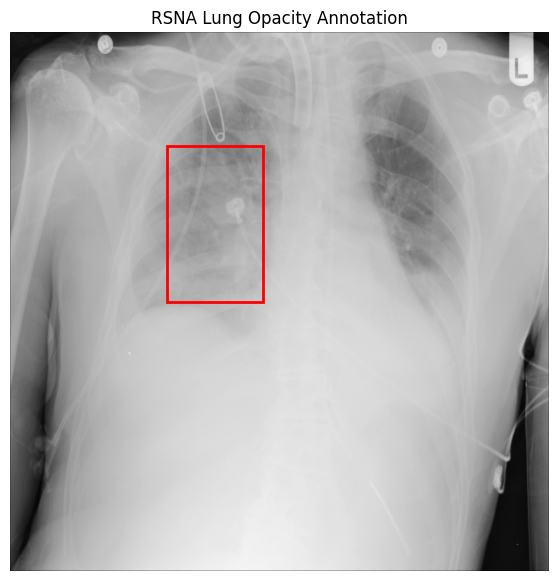

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

positive_dcm = pydicom.dcmread(positive_paths[0])
image = positive_dcm.pixel_array

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(image, cmap="gray")

rect = patches.Rectangle(
    (
        positive_example["x"],
        positive_example["y"]
    ),
    positive_example["bbox_width"],
    positive_example["bbox_height"],
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(rect)

ax.set_title("RSNA Lung Opacity Annotation")
ax.axis("off")

plt.show()


## 6. Constructing the Image-Level Modeling Dataset

We construct a modeling dataset containing one record for each unique combination of study, series, image identifier, and final classification label.

### Binary Target Definition

The classification target is defined as:

- **1:** Lung Opacity
- **0:** No Lung Opacity, including Normal and No Lung Opacity / Not Normal

This target will be used to train the ResNet50 classifier in the next notebook.

### Linking Image Files

We create a lookup between SOP Instance UIDs and extracted DICOM file paths.

Each modeling record is then matched to its corresponding image file.

We verify the number of successfully matched images and check for missing paths.

### Resulting Dataset

The resulting dataset contains 29,684 image records, as verified later in the notebook.

This differs from the 30,000 DICOM files in the archive because the modeling dataset is constructed from the selected annotation categories and matching records.

### Relevance to the Project

The image-level modeling dataset provides the labels and image references used for training and evaluating the classifier.

It also provides the identifiers needed to select and consistently track images across the subsequent XAI experiments.


In [ ]:
model_df = (
    final_df[
        ["study_uid", "series_uid", "sop_uid", "final_label"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Number of images:", len(model_df))
print()
print(model_df["final_label"].value_counts())

Number of images: 29684

final_label
No Lung Opacity / Not Normal    12788
Normal                           9790
Lung Opacity                     7106
Name: count, dtype: int64


In [ ]:
# create binary classification target
model_df["target"] = (
    model_df["final_label"] == "Lung Opacity"
).astype(int)

model_df["target"].value_counts()

,count
target,
0,22578
1,7106


In [ ]:
path_lookup = {
    p.stem: str(p)
    for p in current_dicom_files
}

print("Paths indexed:", len(path_lookup))

Paths indexed: 30000


In [ ]:
model_df["image_path"] = model_df["sop_uid"].map(path_lookup)

print(
    "Images with matching DICOM:",
    model_df["image_path"].notna().sum()
)

print(
    "Images without matching DICOM:",
    model_df["image_path"].isna().sum()
)

Images with matching DICOM: 29684
Images without matching DICOM: 0


In [ ]:
model_df.head()

,study_uid,series_uid,sop_uid,final_label,target,image_path
0,1.2.276.0.7230010.3.1.2.8323329.20779.15178744...,1.2.276.0.7230010.3.1.3.8323329.20779.15178744...,1.2.276.0.7230010.3.1.4.8323329.20779.15178744...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...
1,1.2.276.0.7230010.3.1.2.8323329.19863.15178744...,1.2.276.0.7230010.3.1.3.8323329.19863.15178744...,1.2.276.0.7230010.3.1.4.8323329.19863.15178744...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...
2,1.2.276.0.7230010.3.1.2.8323329.12963.15178743...,1.2.276.0.7230010.3.1.3.8323329.12963.15178743...,1.2.276.0.7230010.3.1.4.8323329.12963.15178743...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...
3,1.2.276.0.7230010.3.1.2.8323329.29425.15178744...,1.2.276.0.7230010.3.1.3.8323329.29425.15178744...,1.2.276.0.7230010.3.1.4.8323329.29425.15178744...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...
4,1.2.276.0.7230010.3.1.2.8323329.13765.15178743...,1.2.276.0.7230010.3.1.3.8323329.13765.15178743...,1.2.276.0.7230010.3.1.4.8323329.13765.15178743...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...


In [ ]:
model_df.groupby(
    ["final_label", "target"]
).size()

,,0
final_label,target,
Lung Opacity,1,7106
No Lung Opacity / Not Normal,0,12788
Normal,0,9790


## 7. Extracting Patient Identifiers

Patient identifiers are extracted from DICOM metadata to examine the relationship between images and patients.

### Motivation

Medical imaging datasets may contain multiple images from the same patient.

If images belonging to the same patient appear in both training and evaluation datasets, model performance estimates may be affected by patient-level data leakage.

Therefore, patient identifiers are examined before constructing the final dataset splits.

### Extraction Procedure

The code reads the `PatientID` field from DICOM metadata.

Using `stop_before_pixels=True` allows metadata to be accessed without loading the complete image pixel arrays.

To support recovery from interrupted Colab sessions, extracted identifiers are stored in:

`Data/patient_ids_checkpoint.csv`

### Data Validation

After extracting the patient identifiers, the code:

1. Merges them into the modeling dataset.
2. Checks for missing identifiers.
3. Examines the number of images per patient.
4. Checks whether patients appear with multiple target labels.

### Observed Results

The recorded checks show:

- 29,684 modeling images with patient identifiers.
- One image per extracted patient identifier in this prepared dataset.
- No overlapping patient identifiers across the subsequently constructed training, validation, and test splits.

### Reproducibility and Limitations

Checkpointing allows the extraction process to resume without repeating completed metadata reads.

Patient identifiers also provide a way to verify independence across the dataset splits.

However, checking patient identifiers does not eliminate every possible source of dataset leakage or bias.

In [ ]:
for path in model_df["image_path"].head(5):
    dcm = pydicom.dcmread(path, stop_before_pixels=True)

    print(
        "PatientID:", getattr(dcm, "PatientID", None),
        "| StudyUID:", getattr(dcm, "StudyInstanceUID", None)
    )

PatientID: 3129f567-c659-42f8-b4e1-8a5e3827b477 | StudyUID: 1.2.276.0.7230010.3.1.2.8323329.20779.1517874429.737066
PatientID: 2d37e84a-0e82-4fc4-b20a-de306a63ca67 | StudyUID: 1.2.276.0.7230010.3.1.2.8323329.19863.1517874420.264603
PatientID: 309c2bb5-826b-4e7d-9bdb-9808d9450064 | StudyUID: 1.2.276.0.7230010.3.1.2.8323329.12963.1517874368.590213
PatientID: 2fe3ba48-ce4d-42a4-8eda-99e3eb40d5fe | StudyUID: 1.2.276.0.7230010.3.1.2.8323329.29425.1517874491.819966
PatientID: 30a4932f-d7b3-4727-b0bc-72605b530913 | StudyUID: 1.2.276.0.7230010.3.1.2.8323329.13765.1517874374.516749


In [ ]:
PATIENT_ID_CHECKPOINT = DATA_DIR / "patient_ids_checkpoint.csv"

# Load previous progress if it exists
if PATIENT_ID_CHECKPOINT.exists():
    patient_df = pd.read_csv(PATIENT_ID_CHECKPOINT)
    print(f"Resuming from checkpoint: {len(patient_df)} images already processed.")
else:
    patient_df = pd.DataFrame(columns=["sop_uid", "patient_id"])
    print("Starting patient ID extraction.")

# UIDs already completed
completed_uids = set(patient_df["sop_uid"].astype(str))

new_rows = []

total = len(model_df)

for i, row in model_df.iterrows():

    sop_uid = str(row["sop_uid"])

    # Skip images already processed
    if sop_uid in completed_uids:
        continue

    try:
        dcm = pydicom.dcmread(
            row["image_path"],
            stop_before_pixels=True,
            specific_tags=["PatientID"]
        )

        patient_id = str(dcm.PatientID)

    except Exception as e:
        patient_id = None
        print(f"Problem reading {sop_uid}: {e}")

    new_rows.append({
        "sop_uid": sop_uid,
        "patient_id": patient_id
    })

    # Save every 250 newly processed images
    if len(new_rows) >= 250:

        patient_df = pd.concat(
            [patient_df, pd.DataFrame(new_rows)],
            ignore_index=True
        )

        patient_df.to_csv(PATIENT_ID_CHECKPOINT, index=False)

        new_rows = []

        print(
            f"Saved progress: "
            f"{len(patient_df):,} / {total:,} images"
        )

# Save the final partial batch
if new_rows:
    patient_df = pd.concat(
        [patient_df, pd.DataFrame(new_rows)],
        ignore_index=True
    )

    patient_df.to_csv(PATIENT_ID_CHECKPOINT, index=False)

print(f"\nFinished: {len(patient_df):,} / {total:,} images")

Starting patient ID extraction.
Saved progress: 250 / 29,684 images
Saved progress: 500 / 29,684 images
Saved progress: 750 / 29,684 images
Saved progress: 1,000 / 29,684 images
Saved progress: 1,250 / 29,684 images
Saved progress: 1,500 / 29,684 images
Saved progress: 1,750 / 29,684 images
Saved progress: 2,000 / 29,684 images
Saved progress: 2,250 / 29,684 images
Saved progress: 2,500 / 29,684 images
Saved progress: 2,750 / 29,684 images
Saved progress: 3,000 / 29,684 images
Saved progress: 3,250 / 29,684 images
Saved progress: 3,500 / 29,684 images
Saved progress: 3,750 / 29,684 images
Saved progress: 4,000 / 29,684 images
Saved progress: 4,250 / 29,684 images
Saved progress: 4,500 / 29,684 images
Saved progress: 4,750 / 29,684 images
Saved progress: 5,000 / 29,684 images
Saved progress: 5,250 / 29,684 images
Saved progress: 5,500 / 29,684 images
Saved progress: 5,750 / 29,684 images
Saved progress: 6,000 / 29,684 images
Saved progress: 6,250 / 29,684 images
Saved progress: 6,500 / 

### 7.1 Integrating and Validating Patient Identifiers

After extracting patient identifiers from DICOM metadata, we merge them into the image-level modeling dataset using `SOPInstanceUID`.

The merge uses a one-to-one validation to check that the patient-ID records correspond uniquely to the modeling records.

We then verify:

- The total number of images remains unchanged.
- Every modeling image has a patient identifier.
- The distribution of images per patient.
- Whether patients have images belonging to multiple target classes.

**Observed results:**

- 29,684 images successfully matched to patient identifiers.
- No missing patient identifiers.
- One image per patient identifier in the prepared dataset.
- No patients associated with both target classes.

These checks support the subsequent evaluation of patient-level independence across dataset splits.

In [ ]:
# Merge extracted PatientIDs back into model_df

model_df = model_df.drop(
    columns=["patient_id"],
    errors="ignore"
)

model_df = model_df.merge(
    patient_df[["sop_uid", "patient_id"]],
    on="sop_uid",
    how="left",
    validate="one_to_one"
)

print("Images:", len(model_df))
print("Patient IDs matched:", model_df["patient_id"].notna().sum())
print("Missing Patient IDs:", model_df["patient_id"].isna().sum())

assert len(model_df) == 29684
assert model_df["patient_id"].notna().all()

print("✓ Patient IDs successfully added to model_df.")

Images: 29684
Patient IDs matched: 29684
Missing Patient IDs: 0
✓ Patient IDs successfully added to model_df.


In [ ]:
images_per_patient = model_df.groupby("patient_id").size()

print("\nImages per patient:")
print(images_per_patient.describe())

print("\nPatients with >1 image:")
print((images_per_patient > 1).sum())


Images per patient:
count    29684.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
dtype: float64

Patients with >1 image:
0


In [ ]:
patient_target_counts = (
    model_df.groupby("patient_id")["target"]
    .nunique()
)

print(
    "Patients appearing with both target classes:",
    (patient_target_counts > 1).sum()
)

Patients appearing with both target classes: 0


## 8. Creating Training, Validation, and Test Splits

The modeling dataset is divided into training, validation, and test subsets.

### Split Strategy

The code uses stratified random splitting with `random_state=42`.

The dataset is divided as follows:

| Subset | Percentage | Number of Images |
|---|---:|---:|
| Training | 70% | 20,778 |
| Validation | 15% | 4,453 |
| Test | 15% | 4,453 |

Stratification helps preserve the distribution of the binary target variable across the subsets.

### Purpose of Each Subset

**Training Set**

Used to fit the ResNet-50 classification model.

**Validation Set**

Used to evaluate model performance during development and select the model checkpoint.

**Test Set**

Reserved for held-out model evaluation and subsequent explanation analysis.

### Reproducibility

The fixed random seed (`random_state=42`) makes the split assignment reproducible when the input dataset and row ordering remain unchanged.

The final assignments are saved in:

`Data/model_dataset_split.csv`

Saving the assignments allows subsequent notebooks to reuse the same subsets without independently regenerating them.

The code also checks the saved dataset and avoids overwriting an existing split file.

### Patient-Level Independence

The code performs image-level stratified splitting rather than an explicitly patient-grouped split.

However, the patient-identifier checks in this dataset show one image per patient identifier and no patient-ID overlap across the three subsets.

These checks support patient-disjoint evaluation according to the available identifiers.

### Connection to the XAI Evaluation

The later XAI experiments use a selected subset of held-out images.

The final analysis includes 300 held-out images:

- 150 positive images.
- 150 negative images.

The primary stability–localization disagreement audit uses the 150 annotated positive images because localization alignment is evaluated against available opacity bounding boxes.

### Limitation

The selected 300-image XAI subset is smaller than the full test partition.

Therefore, the XAI findings should not automatically be interpreted as representative of every image in the full RSNA dataset.

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    model_df,
    test_size=0.30,
    stratify=model_df["target"],
    random_state=42
)

In [ ]:
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["target"],
    random_state=42
)

In [ ]:
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nPositive proportions:")
print("Train:", train_df["target"].mean())
print("Validation:", val_df["target"].mean())
print("Test:", test_df["target"].mean())

Train: 20778
Validation: 4453
Test: 4453

Positive proportions:
Train: 0.2393878140340745
Validation: 0.2393891758365147
Test: 0.2393891758365147


In [ ]:
model_df["split"] = None

model_df.loc[train_df.index, "split"] = "train"
model_df.loc[val_df.index, "split"] = "validation"
model_df.loc[test_df.index, "split"] = "test"

print(model_df["split"].value_counts())

print("\nMissing split assignments:")
print(model_df["split"].isna().sum())

split
train         20778
validation     4453
test           4453
Name: count, dtype: int64

Missing split assignments:
0


In [ ]:
SPLIT_PATH = DATA_DIR / "model_dataset_split.csv"

if SPLIT_PATH.exists():
    print("Split file already exists. Not overwriting.")
    print("Path:", SPLIT_PATH)

    saved_df = pd.read_csv(SPLIT_PATH)

    print("Rows:", len(saved_df))
    print(saved_df["split"].value_counts())

else:
    model_df.to_csv(
        SPLIT_PATH,
        index=False
    )

    print("Saved to:", SPLIT_PATH)

Saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Data/model_dataset_split.csv


In [ ]:
saved_df = pd.read_csv(SPLIT_PATH)
assert len(saved_df) == 29684, (
    f"Expected 29684 rows, found {len(saved_df)}"
)

assert saved_df["image_path"].notna().all(), (
    "Some images are missing DICOM paths."
)

assert saved_df["patient_id"].notna().all(), (
    "Some images are missing PatientIDs."
)

assert saved_df["split"].notna().all(), (
    "Some images are missing split assignments."
)

assert set(saved_df["split"].unique()) == {
    "train", "validation", "test"
}

print("Rows:", len(saved_df))

print("\nSplit counts:")
print(saved_df["split"].value_counts())

print("\nPositive proportions:")
print(saved_df.groupby("split")["target"].mean())

print("Saved dataset:", SPLIT_PATH)

Rows: 29684

Split counts:
split
train         20778
validation     4453
test           4453
Name: count, dtype: int64

Positive proportions:
split
test          0.239389
train         0.239388
validation    0.239389
Name: target, dtype: float64
Saved dataset: /content/drive/MyDrive/XAI_project_Expo_1_folder/Data/model_dataset_split.csv


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/model_dataset_split.csv"
)

# Exclude missing patient IDs
df = df.dropna(subset=["patient_id"])

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    patients_a = set(df.loc[df["split"] == a, "patient_id"])
    patients_b = set(df.loc[df["split"] == b, "patient_id"])

    overlap = patients_a & patients_b

    print(f"{a} vs {b}: {len(overlap)} overlapping patients")

train vs validation: 0 overlapping patients
train vs test: 0 overlapping patients
validation vs test: 0 overlapping patients


## Reproducibility Checklist

The following information is needed to reproduce the data preparation workflow:

- [ ] RSNA DICOM images and the corresponding adjudicated annotation JSON are available.
- [ ] The Google Drive project directory is configured correctly.
- [ ] Required Python packages are installed.
- [ ] DICOM extraction is complete and file counts have been verified.
- [ ] Annotation identifiers are matched to the correct DICOM images.
- [ ] The binary classification target uses the documented annotation categories.
- [ ] Patient identifiers have been extracted and checked.
- [ ] Dataset splits use `random_state=42`.
- [ ] The saved split file is reused in downstream notebooks.
- [ ] Data paths and saved artifacts are documented.

### Environment Notes

The notebook was developed in Google Colab. Package versions and the runtime environment can affect exact reproducibility.

For a fully reproducible release, the project should also include a dependency file such as `requirements.txt` and document the Python and package versions used.

### Reproducibility Boundary

This notebook reproduces the data preparation procedure.

Model training, attribution generation, corruption experiments, and the final disagreement audit are documented separately in subsequent notebooks.

## 9. Conclusion and Next Steps

This notebook establishes the data preparation foundation for the project:

**When Stable Explanations Disagree: A Stability–Localization Disagreement Audit for Chest X-ray Classification**

### Summary of Completed Work

The notebook:

1. Inspected the RSNA annotation structure.
2. Extracted classification labels and available opacity bounding boxes.
3. Verified the extracted DICOM image files.
4. Matched images to their annotations using image identifiers.
5. Constructed a binary lung-opacity classification dataset.
6. Extracted and examined patient identifiers.
7. Created reproducible training, validation, and test assignments.

### Primary Output

The main output is:

`Data/model_dataset_split.csv`

This file contains the image-level modeling information and split assignments used in subsequent notebooks.

Supporting files include:

- `Data/dicom_paths.txt`
- `Data/patient_ids_checkpoint.csv`
- The original adjudicated annotation JSON.

### Reproducibility Summary

Several decisions support reproducibility:

- Preserving DICOM image identifiers for consistent annotation matching.
- Saving image paths and patient identifiers.
- Fixing the random seed for dataset splitting.
- Saving split assignments for reuse.
- Verifying file counts, missing paths, and patient overlap.

To reproduce the workflow, researchers must obtain the RSNA data, configure the appropriate file paths, and use compatible Python package versions.

The saved split assignments should be reused in later notebooks to avoid unintended changes in the evaluation dataset.

### Connection to the Main Research Question

The subsequent notebooks use the prepared data to train a ResNet-50 classifier and evaluate three explanation methods:

- Integrated Gradients
- Occlusion Sensitivity
- Score-CAM

Explanations are compared under six image-corruption conditions:

- Mild, moderate, and severe Gaussian blur.
- Mild, moderate, and severe Gaussian noise.

The final disagreement audit examines whether high explanation stability can coexist with reduced localization alignment.

The primary audit contains:

150 annotated positive images × 3 XAI methods × 6 corruption conditions = **2,700 evaluations**.

These evaluations represent repeated method–image–corruption observations rather than 2,700 independent patients.

### Limitations

- The classification target is based on dataset-defined lung-opacity categories, not comprehensive clinical diagnoses.
- Radiologist bounding boxes provide localization references but do not establish explanation faithfulness.
- The analysis uses one dataset and one classifier architecture.
- The later disagreement thresholds are exploratory and have not been clinically validated.
- Patient-ID checks do not rule out every source of dataset bias or leakage.

### Next Steps

Proceed to Notebook 02 to train and evaluate the ResNet-50 classifier using the prepared dataset and saved split assignments.

The subsequent XAI notebooks will generate attribution maps, evaluate explanation behavior under corruption, and conduct the stability–localization disagreement audit.